# Phi-3 · Aprendizaje por retroalimentación humana

DistilBERT estima cuál de dos respuestas para la misma solicitud se ajusta mejor a las preferencias de HH-RLHF. A partir del adaptador SFT de Phi-3, PPO optimiza esa señal con una penalización por alejarse de la política de referencia. El cuaderno de [evaluación](evaluacion.ipynb) compara la política resultante con zero-shot, few-shot y SFT.

Usa el kernel **Tarea 3 (GPU)** o **rocm (3.14.10)** en VS Code. El [entrenamiento SFT](entrenamiento.ipynb) debe haber guardado el adaptador en `salidas/sft_lr5e5/`.

In [1]:
from pathlib import Path
import sys

folder = Path.cwd() if Path("comun.py").is_file() else Path.cwd() / "tarea3"
if not (folder / "comun.py").is_file():
    raise FileNotFoundError("Abre el cuaderno desde la carpeta tarea3 o la raiz del repositorio.")
sys.path.insert(0, str(folder))

from comun import preparar_notebook

preparar_notebook()

Python del cuaderno: C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\.runtime\rocm\Scripts\python.exe


In [2]:
import os

from IPython.display import Markdown, display

from comun import OUT, SFT_DIR
from rlhf import (
    PPO_DIR, REWARD_DIR, clear_gpu, confirm_reward, output_name,
    read_json, read_partitions, train_ppo, train_reward,
)

PILOTO = os.getenv("TAREA3_PILOTO") == "1"
if not (OUT / SFT_DIR / "adapter_model.safetensors").is_file():
    raise FileNotFoundError("Ejecuta el entrenamiento SFT completo antes de iniciar RLHF.")

particiones, huellas = read_partitions(PILOTO)
print("Modo:", "piloto" if PILOTO else "final")
for nombre in ("sft", "recompensa_train", "recompensa_val", "ppo"):
    print(f"{nombre}: {len(particiones[nombre])} filas")

Modo: final
sft: 512 filas
recompensa_train: 1024 filas
recompensa_val: 128 filas
ppo: 128 filas


## Modelo de recompensa

Para cada solicitud se puntúan por separado la respuesta preferida y la rechazada. La pérdida es $-\log\sigma(r_\mathrm{preferida}-r_\mathrm{rechazada})$. El máximo es de 512 tokens por par solicitud–respuesta y se reservan hasta 128 para la solicitud.

DistilBERT se reinicia desde el checkpoint preentrenado y se entrena durante seis épocas completas. La tasa máxima es `1e-5`, con calentamiento durante el primer 10 % de los pasos y decaimiento lineal. En validación, la pérdida de `harmless-base` pesa dos tercios y la de `helpful-base` pesa un tercio. Se elige la época con menor pérdida ponderada y se desempata por precisión en `harmless-base` y por la época más temprana.

La confirmación compara los modelos en 512 pares nuevos de cada fuente, después de fijar el checkpoint. La normalización para PPO usa los puntajes de entrenamiento del checkpoint seleccionado.

In [3]:
import torch

torch.set_num_threads(min(torch.get_num_threads(), 8))
ruta_referencia = OUT / output_name(REWARD_DIR, PILOTO)
if not PILOTO or ruta_referencia.is_dir():
    _, referencia = train_reward(particiones, huellas, PILOTO)
else:
    referencia = None
clear_gpu()

ruta_recompensa, recompensa = train_reward(particiones, huellas, PILOTO, six_epochs=True)
clear_gpu()
print(ruta_recompensa)

Reutilizando recompensa en C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\recompensa_distilbert
Reutilizando recompensa en C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\recompensa_distilbert_6e
C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\recompensa_distilbert_6e


Recortes de la candidata: {'train': {'pares_prompt_truncado': 2, 'preferidas_truncadas': 1, 'rechazadas_truncadas': 0}, 'val': {'pares_prompt_truncado': 0, 'preferidas_truncadas': 0, 'rechazadas_truncadas': 0}}


| Corrida | Época elegida | Fuente | Pares | Precisión | Pérdida |
|---|---:|---|---:|---:|---:|
| Referencia | 1 | Total | 128 | 62.5% | 0.6852 |
| Referencia | 1 | helpful-base | 64 | 73.4% | 0.6623 |
| Referencia | 1 | harmless-base | 64 | 51.6% | 0.7081 |
| Candidata | 4 | Total | 128 | 58.6% | 0.6677 |
| Candidata | 4 | helpful-base | 64 | 59.4% | 0.6465 |
| Candidata | 4 | harmless-base | 64 | 57.8% | 0.6890 |

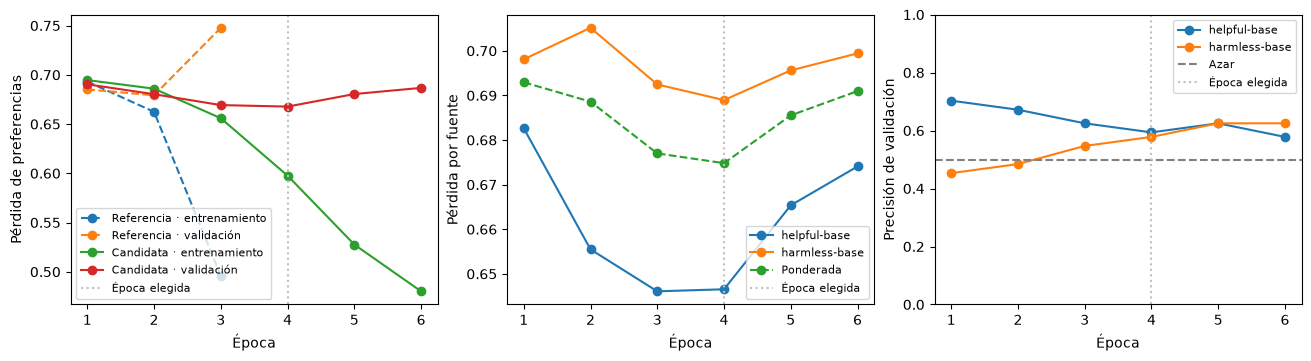

In [4]:
import matplotlib.pyplot as plt

filas = [
    "| Corrida | Época elegida | Fuente | Pares | Precisión | Pérdida |",
    "|---|---:|---|---:|---:|---:|",
]
corridas = [("Referencia", referencia), ("Candidata", recompensa)]
for nombre, corrida in corridas:
    if corrida is None:
        continue
    validacion = corrida["validacion"]
    por_fuente = {"Total": validacion, **validacion["por_fuente"]}
    for fuente in por_fuente:
        metricas = por_fuente[fuente]
        filas.append(f"| {nombre} | {corrida['mejor_epoca']} | {fuente} | {metricas['pares']} | "
                     f"{metricas['accuracy']:.1%} | {metricas['loss']:.4f} |")
display(Markdown("\n".join(filas)))
print("Recortes de la candidata:", recompensa["recortes"])

historial = recompensa["historial"]
epocas = [fila["epoca"] for fila in historial]
fig, (ax_loss, ax_fuente, ax_acc) = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for corrida, estilo in ((referencia, "o--"), (recompensa, "o-")):
    if corrida is None:
        continue
    serie = corrida["historial"]
    eje = [fila["epoca"] for fila in serie]
    nombre = "Referencia" if corrida is referencia else "Candidata"
    ax_loss.plot(eje, [fila["loss_train"] for fila in serie], estilo, label=f"{nombre} · entrenamiento")
    ax_loss.plot(eje, [fila["loss"] for fila in serie], estilo, label=f"{nombre} · validación")
for fuente in ("helpful-base", "harmless-base"):
    valores = [fila["por_fuente"][fuente] for fila in historial]
    ax_fuente.plot(epocas, [fila["loss"] for fila in valores], "o-", label=fuente)
    ax_acc.plot(epocas, [fila["accuracy"] for fila in valores], "o-", label=fuente)
ax_fuente.plot(epocas, [fila["loss_ponderada"] for fila in historial], "o--", label="Ponderada")
ax_acc.axhline(.5, color="0.5", linestyle="--", label="Azar")
for ax, ylabel in zip((ax_loss, ax_fuente, ax_acc),
                      ("Pérdida de preferencias", "Pérdida por fuente", "Precisión de validación"), strict=True):
    ax.axvline(recompensa["mejor_epoca"], color="0.75", linestyle=":", label="Época elegida")
    ax.set(xlabel="Época", ylabel=ylabel, xticks=epocas)
    ax.legend(fontsize=8)
ax_acc.set_ylim(0, 1)
plt.show()

In [5]:
confirmacion = None
if PILOTO:
    print("Piloto: la confirmación se ejecuta sobre la corrida de seis épocas.")
else:
    confirmacion = confirm_reward(particiones, huellas, ruta_recompensa, recompensa)
    clear_gpu()
    filas = [
        "| Fuente | Pares | Precisión referencia | Precisión candidata | Cambio | Pérdida referencia | Pérdida candidata |",
        "|---|---:|---:|---:|---:|---:|---:|",
    ]
    for fuente in confirmacion["por_fuente"]:
        antes = confirmacion["referencia"]["por_fuente"][fuente]
        despues = confirmacion["candidata"]["por_fuente"][fuente]
        pares = confirmacion["por_fuente"][fuente]
        filas.append(f"| {fuente} | {pares['pares']} | {antes['accuracy']:.2%} | {despues['accuracy']:.2%} | "
                     f"{pares['delta_accuracy'] * 100:+.2f} pp | {antes['loss']:.4f} | {despues['loss']:.4f} |")
    display(Markdown("\n".join(filas)))
    harmless = confirmacion["por_fuente"]["harmless-base"]
    print(f"McNemar unilateral en harmless-base: p={harmless['p_mcnemar_unilateral']:.4g} "
          f"({harmless['ganadas']} mejoras y {harmless['perdidas']} retrocesos).")
    for criterio, texto in (
        ("harmless_mejora_minima", "Mejora de harmless-base de al menos 5 pp"),
        ("harmless_mcnemar", "McNemar unilateral con p ≤ 0,05"),
        ("harmless_perdida", "Pérdida de harmless-base igual o menor"),
        ("helpful_tolerancia", "Caída de helpful-base de hasta 5 pp"),
    ):
        print(f"{texto}: {'cumple' if confirmacion['criterios'][criterio] else 'no cumple'}.")
    print("Decisión:", "entrenar PPO con la candidata" if confirmacion["aprobada"]
          else "conservar PPO de referencia.")

McNemar unilateral en harmless-base: p=9.153e-05 (120 mejoras y 68 retrocesos).
Mejora de harmless-base de al menos 5 pp: cumple.
McNemar unilateral con p ≤ 0,05: cumple.
Pérdida de harmless-base igual o menor: cumple.
Caída de helpful-base de hasta 5 pp: cumple.
Decisión: entrenar PPO con la candidata


| Fuente | Pares | Precisión referencia | Precisión candidata | Cambio | Pérdida referencia | Pérdida candidata |
|---|---:|---:|---:|---:|---:|---:|
| helpful-base | 512 | 64.84% | 60.35% | -4.49 pp | 0.6689 | 0.6528 |
| harmless-base | 512 | 46.48% | 56.64% | +10.16 pp | 0.7014 | 0.6819 |

## Optimización PPO

La política y la referencia comienzan con los mismos pesos SFT y comparten Phi-3 cuantizado. Se muestrea una respuesta por solicitud. PPO aplica la recompensa normalizada al último token y descuenta, en cada acción, la diferencia entre el logaritmo de la probabilidad de la política anterior y el de la referencia. Se usa GAE con $\gamma=1$ y $\lambda=0.95$, con valor futuro cero al terminar por EOS o por el límite. La pérdida de política y la de valor usan clipping de 0,2.

Cada lote mezcla dos solicitudes de cada fuente y se actualiza durante dos épocas. La corrida final usa 128 solicitudes y un máximo de 64 tokens por respuesta de entrenamiento. PPO se ejecuta cuando la confirmación independiente cumple los cuatro criterios. Si se interrumpe una corrida, vuelve a ejecutar la celda para retomar desde el último checkpoint compatible.

In [6]:
reporte_ppo = None
if confirmacion and confirmacion["aprobada"]:
    ruta_ppo, reporte_ppo = train_ppo(particiones, huellas, ruta_recompensa, recompensa, PILOTO)
    clear_gpu()
    print(f"Adaptador PPO de la candidata: {ruta_ppo}")
elif not PILOTO:
    referencia_ppo = OUT / PPO_DIR / "reporte.json"
    if referencia_ppo.is_file():
        reporte_ppo = read_json(referencia_ppo)
        print(f"PPO vigente (referencia): {referencia_ppo.parent}")

Reutilizando adaptador PPO completo en C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\ppo_lr3e6_6e
Adaptador PPO de la candidata: C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\ppo_lr3e6_6e


Lotes: 32 · Respuestas muestreadas: 128 · Vacías: 3
Referencia intacta: True · Política actualizada: True · Valor actualizado: True


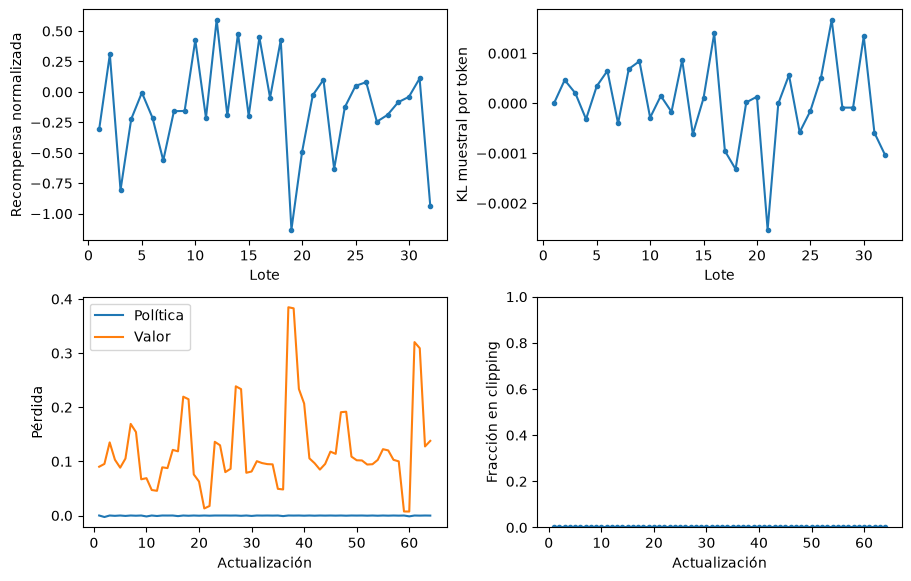

In [7]:
if reporte_ppo is not None:
    lotes = reporte_ppo["historial"]
    pasos = [fila["lote"] for fila in lotes]
    fig, axes = plt.subplots(2, 2, figsize=(9, 5.7), layout="constrained")
    for ax, campo, nombre in zip(
        (axes[0, 0], axes[0, 1]), ("recompensa_normalizada", "kl_por_token"),
        ("Recompensa normalizada", "KL muestral por token"), strict=True,
    ):
        ax.plot(pasos, [fila[campo] for fila in lotes], ".-")
        ax.set(xlabel="Lote", ylabel=nombre)
    actualizaciones = [u for lote in lotes for u in lote["actualizaciones"]]
    pasos_ppo = range(1, len(actualizaciones) + 1)
    axes[1, 0].plot(pasos_ppo, [u["loss_politica"] for u in actualizaciones], label="Política")
    axes[1, 0].plot(pasos_ppo, [u["loss_valor"] for u in actualizaciones], label="Valor")
    axes[1, 0].set(xlabel="Actualización", ylabel="Pérdida")
    axes[1, 0].legend()
    axes[1, 1].plot(pasos_ppo, [u["fraccion_clip"] for u in actualizaciones], ".-")
    axes[1, 1].set(xlabel="Actualización", ylabel="Fracción en clipping", ylim=(0, 1))
    plt.show()
    print(f"Lotes: {len(lotes)} · Respuestas muestreadas: "
          f"{sum(len(fila['prompts']) for fila in lotes)} · Vacías: {sum(fila['vacias'] for fila in lotes)}")
    print(f"Referencia intacta: {reporte_ppo['referencia_intacta']} · "
          f"Política actualizada: {reporte_ppo['politica_actualizada']} · "
          f"Valor actualizado: {reporte_ppo['valor_actualizado']}")

## Lectura de resultados

La precisión indica qué tan seguido el modelo de recompensa ordena correctamente los pares de validación. Las curvas PPO describen la señal que optimizó la política durante el muestreo. En la [evaluación comparativa](evaluacion.ipynb), Toxic-BERT puntúa las respuestas y la revisión humana mide seguridad, utilidad y rechazos innecesarios con los mismos prompts para las cuatro configuraciones.

Referencias metodológicas. [HH-RLHF](https://huggingface.co/datasets/Anthropic/hh-rlhf), [PPO](https://arxiv.org/abs/1707.06347) y [GAE](https://arxiv.org/abs/1506.02438).